In [1]:
# mount google colab with drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Problem Statment

Online communities and social media platforms have become integral parts of modern communication, facilitating interactions and discussions on various topics. However, the prevalence of toxic comments, which include harassment, hate speech, and offensive language, poses significant challenges to maintaining healthy and constructive online discourse.
To address this issue, there is a pressing need for automated systems capable of detecting and flagging toxic comments in real-time.


Import Libreries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Data Collection

In [3]:
df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Pending Projects/Comment Toxicity Project/train.csv')

Dataset Copy

In [4]:
df_copy=df.copy()

In [5]:
#df=df_copy.copy()

In [6]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [7]:
df.isnull().sum()

,0
id,0
comment_text,0
toxic,0
severe_toxic,0
obscene,0
threat,0
insult,0
identity_hate,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


In [9]:
df.describe()

,toxic,severe_toxic,obscene,threat,insult,identity_hate
count,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000
mean,0.095844,0.009996,0.052948,0.002996,0.049364,0.008805
std,0.294379,0.099477,0.223931,0.054650,0.216627,0.093420
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Text Preprocessing

1. Convert into Lower Case.

In [10]:
# Conerting text Upper To Lower.
df['comment_text']=df['comment_text'].str.lower()


In [11]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,explanation\nwhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,d'aww! he matches this background colour i'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"hey man, i'm really not trying to edit war. it...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nmore\ni can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"you, sir, are my hero. any chance you remember...",0,0,0,0,0,0


2.Remove HTML Tags

In [12]:
import re
def remove_tags(df):
  pattern=re.compile('<.*?>')
  return pattern.sub(r'',df)

In [13]:
df['comment_text']=df['comment_text'].apply(remove_tags)

In [14]:
df


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,explanation\nwhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,d'aww! he matches this background colour i'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"hey man, i'm really not trying to edit war. it...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nmore\ni can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"you, sir, are my hero. any chance you remember...",0,0,0,0,0,0
...,...,...,...,...,...,...,...,...
159566,ffe987279560d7ff,""":::::and for the second time of asking, when ...",0,0,0,0,0,0
159567,ffea4adeee384e90,you should be ashamed of yourself \n\nthat is ...,0,0,0,0,0,0
159568,ffee36eab5c267c9,"spitzer \n\numm, theres no actual article for ...",0,0,0,0,0,0
159569,fff125370e4aaaf3,and it looks like it was actually you who put ...,0,0,0,0,0,0


3. Remove URL , special characters, extra space and \n.

In [15]:
import re

def remove_urls(text):
  if not isinstance(text,str):
    text=str(text)
  text=re.sub(r'\d+',' ',text)

  pattern = re.compile(r'https?://\S+|www\.\S+')
  text=pattern.sub(r' ',text)

# remove \n
  text=re.sub(r'\n',' ',text)


# remove special characters
  text=re.sub(r'[^a-zA-Z\s]',' ',text)


# remove extra space
  text=re.sub(r'\s+',' ',text)
  return text.strip()
#
df['comment_text']=df['comment_text'].apply(remove_urls)


In [16]:
df.head(4)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,explanation why the edits made under my userna...,0,0,0,0,0,0
1,000103f0d9cfb60f,d aww he matches this background colour i m se...,0,0,0,0,0,0
2,000113f07ec002fd,hey man i m really not trying to edit war it s...,0,0,0,0,0,0
3,0001b41b1c6bb37e,more i can t make any real suggestions on impr...,0,0,0,0,0,0


4. Tokenization

In [17]:
pip install nltk

In [18]:
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [19]:

#for null value
df['comment_text']=df['comment_text'].fillna('')
df['tokens']=df['comment_text'].apply(word_tokenize)

In [20]:
df['tokens']

,tokens
0,"[explanation, why, the, edits, made, under, my..."
1,"[d, aww, he, matches, this, background, colour..."
2,"[hey, man, i, m, really, not, trying, to, edit..."
3,"[more, i, can, t, make, any, real, suggestions..."
4,"[you, sir, are, my, hero, any, chance, you, re..."
...,...
159566,"[and, for, the, second, time, of, asking, when..."
159567,"[you, should, be, ashamed, of, yourself, that,..."
159568,"[spitzer, umm, theres, no, actual, article, fo..."
159569,"[and, it, looks, like, it, was, actually, you,..."


5. Lemmatization

In [21]:
import spacy
nlp=spacy.load('en_core_web_sm',disable=['parser','ner'])

In [22]:
df[df['comment_text'].apply(type)==float]

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,tokens


In [23]:
df['comment_text']=df['comment_text'].fillna('')

In [24]:
df['comment_text'].apply(type).value_counts()

,count
comment_text,
<class 'str'>,159571


In [27]:
# Handle missing values
df["comment_text"] = df["comment_text"].fillna("").astype(str)

# Process comments in batches
lemmatized_text = []

for doc in nlp.pipe(df["comment_text"], batch_size=1000):
    lemmatized_text.append(
        " ".join(token.lemma_ for token in doc)
    )

df["comment_text"] = lemmatized_text

print("Lemmatization completed!")

Lemmatization completed!


In [28]:
#df.to_csv('toxic_comment_lemmatization.csv',index=False)

In [29]:
#df = pd.read_csv(   '/content/drive/MyDrive/toxic_comment_lemmatization.csv')


Maximum Comment Length

In [30]:
df['comment_text'].describe()

,comment_text
count,159571
unique,158204
top,january
freq,22


In [31]:
df['comment_text']=df['comment_text'].fillna('')
df['comment_length'] = df['comment_text'].apply(len)
df.sort_values('comment_length',ascending=False)[['comment_text','comment_length']].head()

,comment_text,comment_length
156437,huge faggot huge faggot huge faggot huge faggo...,5000
35316,marxismlong live anonymous philippineslong liv...,5000
42061,wanker wanker wanker wanker wanker wanker wank...,5000
93952,wiki noobs wiki noobs wiki noobs wiki noobs wi...,5000
57173,fuck off jewish ancestryfuck off jewish ancest...,5000


In [32]:
df['comment_length'].describe()

,comment_length
count,159571.000000
mean,357.159998
std,539.282933
min,0.000000
25%,84.000000
50%,184.000000
75%,396.000000
max,5000.000000


we can say that from above observation that average comment length is 369 and the medium comment length is 191 maximum comment length is 5000.

In [33]:
#No. Of comments having minimum length
(df['comment_length']==0).sum()

np.int64(15)

Drop the comment which have 0 length.

In [34]:
#df=df.drop(df[df['comment_length']==0].index)

## Label Distribution

In [35]:
labels_cor=[
    'toxic','severe_toxic','obscene','threat','insult','identity_hate'
]
df[labels_cor].sum()

,0
toxic,15294
severe_toxic,1595
obscene,8449
threat,478
insult,7877
identity_hate,1405


From above observation we can say the dataset is highly imbalanced , therat are a rare comments and mostly the comments are non-toxic.

Correlation HeatMap

In [36]:
corr=df[labels_cor].corr()

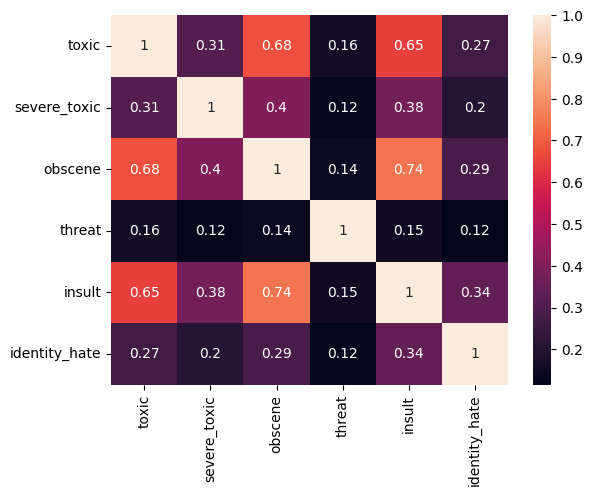

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(corr,annot=True)
plt.show()

### Word Cloud

In [38]:
from wordcloud import WordCloud

For Toxic Comments

In [39]:
toxic_text=" ".join(df[df['toxic']==1]['comment_text'])

wc=WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(toxic_text)

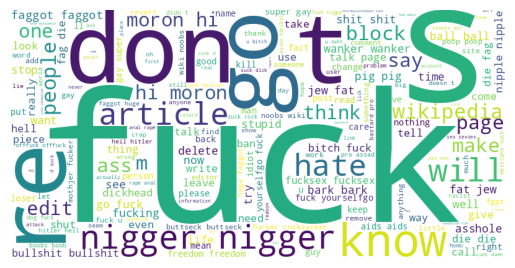

In [40]:
plt.imshow(wc)
plt.axis("off")
plt.show()

For Non Toxic Comments

In [41]:
normal_text=" ".join(df[df['toxic']==0]['comment_text'])

wc=WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(normal_text)

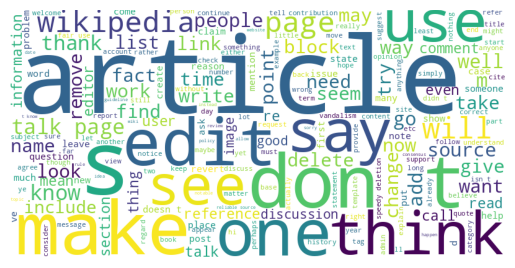

In [42]:
plt.imshow(wc)
plt.axis("off")
plt.show()

## Split the Dataset

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib
x_train,x_test,y_train,y_test=train_test_split(df['comment_text'],
                                               df[labels_cor],
                                               test_size=0.20,
                                               random_state=42)
# gives maximum 50000 unique words rest are ignore, and remove the Articles in english which are not used in predicition.
vectorize=TfidfVectorizer(max_features=50000,
                          stop_words='english',
                          ngram_range=(1,2),
                          min_df=2)
# fit and transform the train dataset
x_train=vectorize.fit_transform(x_train)
# Only transform train dataset.
x_test=vectorize.transform(x_test)

print("shape of x_train",x_train.shape)
print("shape of x_test",x_test.shape)

joblib.dump(vectorize,'tfidf_vectorizer.pkl')

shape of x_train (127656, 50000)
shape of x_test (31915, 50000)


['tfidf_vectorizer.pkl']

## Model Training

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score,classification_report
import joblib

model=OneVsRestClassifier(
    LogisticRegression(max_iter=1000)
)
# fit the model
model.fit(x_train,y_train)

# make prediction on unseen data

prediction=model.predict(x_test)
accuracy=accuracy_score(y_test,prediction)

print(f"Model Accuracy:.{accuracy*100:.2f}%")
print("\nDetailed Performance Report\n")
print(classification_report(y_test,prediction))

joblib.dump(model,'trained_unbalanced_model.pkl')

Model Accuracy:.91.77%

Detailed Performance Report

              precision    recall  f1-score   support

           0       0.91      0.61      0.73      3056
           1       0.54      0.20      0.29       321
           2       0.92      0.62      0.74      1715
           3       0.60      0.12      0.20        74
           4       0.82      0.50      0.62      1614
           5       0.79      0.14      0.24       294

   micro avg       0.88      0.54      0.67      7074
   macro avg       0.76      0.37      0.47      7074
weighted avg       0.87      0.54      0.66      7074
 samples avg       0.06      0.05      0.05      7074



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


['trained_model.pkl']

With class balanced

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score,classification_report

model=OneVsRestClassifier(
    LogisticRegression(max_iter=1000,class_weight='balanced')
)
# fit the model
model.fit(x_train,y_train)

# make prediction on unseen data

prediction=model.predict(x_test)
accuracy=accuracy_score(y_test,prediction)

print(f"Model Accuracy:.{accuracy*100:.2f}%")
print("\nDetailed Performance Report\n")
print(classification_report(y_test,prediction))
joblib.dump(model,'trained_balanced_model.pkl')


Model Accuracy:.87.85%

Detailed Performance Report

              precision    recall  f1-score   support

           0       0.66      0.85      0.74      3056
           1       0.27      0.82      0.40       321
           2       0.70      0.89      0.78      1715
           3       0.18      0.70      0.28        74
           4       0.57      0.85      0.68      1614
           5       0.24      0.76      0.36       294

   micro avg       0.56      0.85      0.68      7074
   macro avg       0.44      0.81      0.54      7074
weighted avg       0.61      0.85      0.70      7074
 samples avg       0.06      0.08      0.07      7074



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Reality Check

In [46]:
comm=['This is fucking vidoes']
comm_vec=vectorize.transform(comm)
prediction=model.predict(comm_vec)


labels = [
    'toxic',
    'severe_toxic',
    'obscene',
    'threat',
    'insult',
    'identity_hate'
]

comments = [
    "Thank you very much",
    "I hate you",
    "Have a nice day"
]

for c in comments:
    vec = vectorize.transform([c])
    pred = model.predict(vec)
    print(c)
    print(pred)
    print("-"*30)

Thank you very much
[[0 0 0 0 0 0]]
------------------------------
I hate you
[[1 0 0 0 1 1]]
------------------------------
Have a nice day
[[0 0 0 0 0 0]]
------------------------------


In [47]:
prediction.shape

(1, 6)